# "SAUDI IS BURNING"
One misleading tweet, four notes, and why only one note was shown on X.

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd

TWEET_FOLDER = "dataset/tweet_2109031558967615703/"
HELPFUL_NOTE_ID = "2109061654621098457"

# ids are 19 digits, read them as strings so pandas doesn't round them
ID_COLUMNS = {
    "noteId": str,
    "tweetId": str,
    "noteAuthorParticipantId": str,
    "raterParticipantId": str,
    "participantId": str,
    "tweet_author_id": str,
}

combined = pd.read_csv(TWEET_FOLDER + "combined.csv", dtype=ID_COLUMNS)
notes = pd.read_csv(TWEET_FOLDER + "notes.csv", dtype=ID_COLUMNS)
status = pd.read_csv(TWEET_FOLDER + "note_status.csv", dtype=ID_COLUMNS)
ratings = pd.read_csv(TWEET_FOLDER + "ratings.csv", dtype=ID_COLUMNS)
requests = pd.read_csv(TWEET_FOLDER + "note_requests.csv", dtype=ID_COLUMNS)
enrollment = pd.read_csv(TWEET_FOLDER + "user_enrollment.csv", dtype=ID_COLUMNS)

# 500-note dataset, to compare with a typical tweet
all_combined = pd.read_csv("dataset/10-05_10-13/combined.csv", dtype=ID_COLUMNS)

In [2]:
BLUE = "tab:blue"
ORANGE = "tab:orange"
GRAY = "tab:gray"

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.axisbelow"] = True
pd.set_option("display.max_colwidth", None)


# X stores time in milliseconds
def to_utc(millis):
    return pd.to_datetime(millis, unit="ms", utc=True)


# "misleadingFactualError" -> "Factual error"
def readable_name(column, prefix):
    words = re.findall(r"[A-Z][a-z]*", column[len(prefix):])
    return " ".join(words).capitalize()


# name the notes Note 1-4 in the order they were written (Note 4 = the one shown)
notes = notes.sort_values("createdAtMillis").reset_index(drop=True)
NOTE_NAMES = {}
for position, note_id in enumerate(notes["noteId"]):
    NOTE_NAMES[note_id] = f"Note {position + 1}"
NOTE_ORDER = list(NOTE_NAMES.values())

ratings["note"] = ratings["noteId"].map(NOTE_NAMES)
tweet = combined.iloc[0]
tweet_posted = pd.to_datetime(tweet["tweet_created_at"], utc=True)

## 1. The data at a glance

This folder has every row about this one tweet, taken from all of X's Community Notes files.
It has the same files as the 500-note dataset, plus two more:
- `note_requests.csv`: people asking for a note on the tweet.
- `user_enrollment.csv`: the people involved (raters and writers), including whether a writer is an **AI**.

In [3]:
files = {
    "notes.csv": (notes, "one note"),
    "note_status.csv": (status, "X's decision about one note (Helpful or not)"),
    "ratings.csv": (ratings, "one person's rating of one note"),
    "note_requests.csv": (requests, "the note requests for the tweet"),
    "user_enrollment.csv": (enrollment, "one person (rater or note writer)"),
}

file_rows = []
for file_name, (table, one_row_is) in files.items():
    file_rows.append({"file": file_name, "one row is": one_row_is, "rows": len(table)})

pd.DataFrame(file_rows)

,file,one row is,rows
0,notes.csv,one note,4
1,note_status.csv,X's decision about one note (Helpful or not),4
2,ratings.csv,one person's rating of one note,456
3,note_requests.csv,the note requests for the tweet,1
4,user_enrollment.csv,one person (rater or note writer),265


1 tweet, **4 notes**, **456 ratings** by **263 raters**. Only **one** of the four notes (Note 4) was shown on X.

## 2. The tweet
How popular was this tweet compared with a typical tweet in the 500-note dataset?

In [4]:
print("Text:  ", tweet["tweet_text"])
print("Posted:", tweet_posted.strftime("%b %d, %Y %H:%M UTC"))

engagement_columns = {
    "likes": "tweet_like_count",
    "retweets": "tweet_retweet_count",
    "replies": "tweet_reply_count",
    "quotes": "tweet_quote_count",
}

engagement_rows = []
for label, column in engagement_columns.items():
    engagement_rows.append({
        "measure": label,
        "this tweet": int(tweet[column]),
        "median tweet (500-note dataset)": int(all_combined[column].median()),
    })

pd.DataFrame(engagement_rows)

Text:   SAUDI IS BURNING
Posted: Oct 10, 2026 21:21 UTC


,measure,this tweet,median tweet (500-note dataset)
0,likes,2226,3564
1,retweets,222,236
2,replies,1624,240
3,quotes,197,82


A three-word claim, posted after an attack on Riyadh's King Khalid Airport. Its likes are a bit below a typical tweet,
but it has **1,624 replies**, about **7 times** the median. Many replies compared to likes means the tweet caused **argument**.

### 2.1 How fast did the notes come?

In [5]:
helpful_note_status = status[status["noteId"] == HELPFUL_NOTE_ID].iloc[0]

events = [("Tweet posted", tweet_posted)]
for _, note in notes.iterrows():
    events.append((NOTE_NAMES[note["noteId"]] + " written", to_utc(note["createdAtMillis"])))
events.append(("Note 4 becomes Helpful (shown on X)", to_utc(helpful_note_status["timestampMillisOfFirstNonNMRStatus"])))

timeline_rows = []
for event, time in events:
    minutes_after_tweet = (time - tweet_posted).total_seconds() / 60
    timeline_rows.append({
        "event": event,
        "time (UTC)": time.strftime("%b %d %H:%M"),
        "minutes after tweet": round(minutes_after_tweet),
    })

pd.DataFrame(timeline_rows)

,event,time (UTC),minutes after tweet
0,Tweet posted,Oct 10 21:21,0
1,Note 1 written,Oct 10 21:36,16
2,Note 2 written,Oct 10 22:09,48
3,Note 3 written,Oct 10 23:19,118
4,Note 4 written,Oct 10 23:20,120
5,Note 4 becomes Helpful (shown on X),Oct 11 04:50,449


The notes came **very fast**: the first note **16 minutes** after the tweet, and four notes within **2 hours**.
But the note was only shown after **449 minutes (about 7.5 hours)**. For 7.5 hours the tweet had no note.

## 3. The notes

### 3.1 Why did the writers say the tweet is misleading?

In [6]:
misleading_columns = [column for column in notes.columns if column.startswith("misleading")]

reason_rows = []
for _, note in notes.iterrows():
    ticked_reasons = []
    for column in misleading_columns:
        if note[column] == 1:
            ticked_reasons.append(readable_name(column, "misleading"))

    reason_rows.append({
        "note": NOTE_NAMES[note["noteId"]],
        "reasons ticked": ", ".join(ticked_reasons),
    })

pd.DataFrame(reason_rows).set_index("note")

,reasons ticked
note,
Note 1,"Other, Outdated information, Missing important context, Unverified claim as fact"
Note 2,"Factual error, Missing important context, Unverified claim as fact"
Note 3,"Factual error, Missing important context, Unverified claim as fact"
Note 4,"Missing important context, Unverified claim as fact"


All four writers ticked **missing important context** and **unverified claim as fact**, the same top problems
as in the 500-note dataset. Every note ticked **2 to 4 reasons**.

### 3.2 What the notes say, sources and length

In [7]:
note_rows = []
for _, note in notes.iterrows():
    text = note["summary"].replace("&quot;", '"').strip()
    note_rows.append({
        "note": NOTE_NAMES[note["noteId"]],
        "note text": text,
        "links": text.count("http"),
        "length (characters)": len(text),
    })

pd.DataFrame(note_rows).set_index("note")

,note text,links,length (characters)
note,,,
Note 1,"Mario claims saudi arabia is burning after an attack on kkia this is poor journalism . Official GACA statement on the King Khalid Airport attack. The incident resulted in minor injuries only, with no reported deaths. Flight operations were briefly paused for safety checks. https://www.spa.gov.sa/en/N2697867",1,309
Note 2,"Saudi Arabia faces targeted Houthi attacks on Riyadh airport causing localized smoke, fires, damage and disruptions with some casualties, but the country is not broadly burning and operations have resumed after incidents. https://www.reuters.com/world/middle-east/houthi-strikes-riyadh-airport-killed-three-saudis-war-escalates-2026-10-09/ https://www.aljazeera.com/news/2026/10/9/saudi-arabia-reopens-riyadh-airport-after-houthi-attack-kills-three https://www.semafor.com/article/10/09/2026/saudi-arabia-faces-its-toughest-moment-of-war",3,540
Note 3,"Saudi Arabia is not ""burning."" Official reports detail a specific attack on Riyadh's King Khalid International Airport with 12 deaths, ~309 injuries, and localized damage/smoke there (operations suspended), but no widespread fires or national destruction. https://x.com/ksagaca/status/2109037908653211923 https://www.arabnews.com/saudi-arabia/riyadh-airport-attacked-killed-12-people-and-wounded-over-300-more-says-saudi-civil-aviation-agency-3005640 https://apnews.com/article/saudi-yemen-houthi-riyadh-airport-f0e0e6105f33400e37bb20bb9a8130af",3,549
Note 4,"“Saudi is burning” misleadingly implies nationwide fires. Saudi authorities reported an Oct. 10 attack on Riyadh’s King Khalid Airport, with 12 dead and 309 injured. The evidence does not support nationwide fires. https://www.spa.gov.sa/w2697996",1,245


All four notes make the **same main point**: the attack hit **one airport**, the country is not "burning".
All of them link to sources (official Saudi news, Reuters, AP, Al Jazeera).
But they **differ in facts and tone**: Note 1 says "no reported deaths" (the others say 12 dead) and calls it "poor journalism".
Note 4 is calm and quotes the claim directly.

## 4. The note writers
Were the notes written by people or by **AI note writers** (status `apiEarnedIn`)?

In [8]:
all_notes = pd.read_csv("dataset/10-05_10-13/notes.csv", dtype=ID_COLUMNS)
notes_per_writer = all_notes["noteAuthorParticipantId"].value_counts()
writer_status = enrollment.set_index("participantId")["enrollmentState"]

writer_rows = []
for _, note in notes.iterrows():
    writer = note["noteAuthorParticipantId"]
    writer_type = "Human"
    if writer_status[writer] == "apiEarnedIn":
        writer_type = "AI"

    writer_rows.append({
        "note": NOTE_NAMES[note["noteId"]],
        "writer type": writer_type,
        "writer's Helpful notes in the 500-note dataset": notes_per_writer.get(writer, 0),
    })

writers = pd.DataFrame(writer_rows).set_index("note")
writers

,writer type,writer's Helpful notes in the 500-note dataset
note,,
Note 1,Human,0
Note 2,AI,60
Note 3,AI,54
Note 4,Human,1


**Notes 2 and 3 were written by AI**. They are the **two most active writers** of the whole 500-note dataset
(60 and 54 Helpful notes in one week). Notes 1 and 4 were written by **humans**.

## 5. The ratings

In [9]:
note_status = status.set_index("noteId")["currentStatus"]

level_rows = []
for note_id, note_name in NOTE_NAMES.items():
    levels = ratings[ratings["noteId"] == note_id]["helpfulnessLevel"]
    helpful = (levels == "HELPFUL").sum()
    level_rows.append({
        "note": note_name,
        "HELPFUL": helpful,
        "SOMEWHAT_HELPFUL": (levels == "SOMEWHAT_HELPFUL").sum(),
        "NOT_HELPFUL": (levels == "NOT_HELPFUL").sum(),
        "total": len(levels),
        "% Helpful": round(helpful / len(levels) * 100, 1),
        "shown on X": note_status[note_id] == "CURRENTLY_RATED_HELPFUL",
    })

level_counts = pd.DataFrame(level_rows).set_index("note")
level_counts

,HELPFUL,SOMEWHAT_HELPFUL,NOT_HELPFUL,total,% Helpful,shown on X
note,,,,,,
Note 1,87,1,25,113,77.0,False
Note 2,77,3,21,101,76.2,False
Note 3,64,1,12,77,83.1,False
Note 4,135,3,27,165,81.8,True


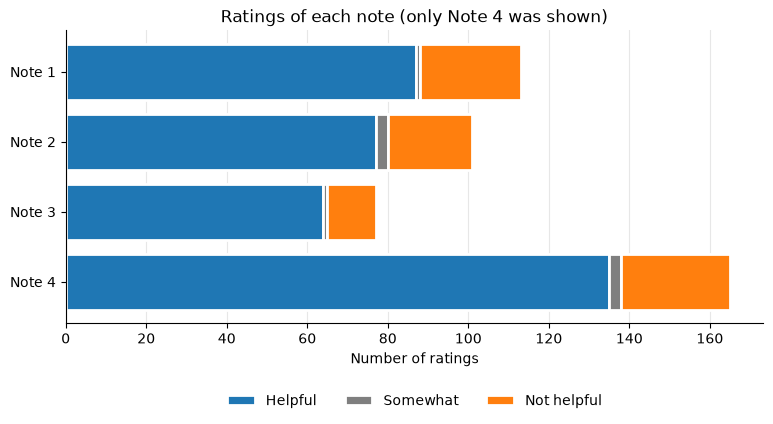

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
left = [0] * len(level_counts)
level_styles = [("HELPFUL", "Helpful", BLUE), ("SOMEWHAT_HELPFUL", "Somewhat", GRAY), ("NOT_HELPFUL", "Not helpful", ORANGE)]

for level, label, color in level_styles:
    values = level_counts[level].tolist()
    ax.barh(level_counts.index, values, left=left, color=color, label=label, edgecolor="white", linewidth=2)
    for row in range(len(values)):
        left[row] += values[row]

ax.invert_yaxis()
ax.set_title("Ratings of each note (only Note 4 was shown)")
ax.set_xlabel("Number of ratings")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
ax.grid(axis="y", visible=False)
plt.show()

**Note 3 had the highest % Helpful (83%)**, but it was **not** shown. Note 4 had 82% and **was** shown.
So a note does not win by having the most Helpful votes. Every note also got some Not Helpful ratings.

### 5.1 The raters

In [11]:
notes_rated_per_rater = ratings["raterParticipantId"].value_counts()
raters_by_notes_rated = notes_rated_per_rater.value_counts().sort_index()

pd.DataFrame({"notes rated": raters_by_notes_rated.index, "raters": raters_by_notes_rated.values})

,notes rated,raters
0,1,162
1,2,44
2,3,22
3,4,35


263 raters. Most (162) rated only one note, but **35 rated all four** and compared them directly.

### 5.2 Why raters found a note Helpful or Not Helpful

In [12]:
# % of each note's ratings (at this level) that ticked each reason
def reason_table(level, prefix):
    reason_columns = []
    for column in ratings.columns:
        is_reason = column.startswith(prefix) and column not in ("helpful", "notHelpful", "helpfulnessLevel")
        if is_reason and ratings[column].sum() > 0:
            reason_columns.append(column)

    rated_at_level = ratings[ratings["helpfulnessLevel"] == level]
    table = rated_at_level.groupby("note")[reason_columns].mean() * 100
    table.columns = [readable_name(column, prefix) for column in reason_columns]
    # transpose: reasons as rows, notes as columns
    return table.T.round(0)


reason_table("HELPFUL", "helpful")

note,Note 1,Note 2,Note 3,Note 4
Other,3.0,4.0,8.0,9.0
Clear,72.0,69.0,72.0,73.0
Good sources,86.0,83.0,81.0,80.0
Addresses claim,67.0,62.0,69.0,67.0
Important context,54.0,55.0,67.0,64.0
Unbiased language,51.0,48.0,53.0,56.0


In [13]:
reason_table("NOT_HELPFUL", "notHelpful")

note,Note 1,Note 2,Note 3,Note 4
Other,4.0,5.0,0.0,11.0
Incorrect,28.0,19.0,17.0,33.0
Sources missing or unreliable,8.0,14.0,25.0,26.0
Missing key points,24.0,43.0,42.0,41.0
Hard to understand,12.0,19.0,25.0,19.0
Argumentative or biased,40.0,24.0,33.0,41.0
Spam harassment or abuse,12.0,14.0,17.0,22.0
Irrelevant sources,20.0,19.0,17.0,26.0
Opinion speculation,20.0,24.0,42.0,37.0
Note not needed,44.0,48.0,67.0,41.0


The reasons are **very similar for all four notes**: Helpful raters praise **good sources** (80–86%) and **clarity** (about 70%).
Many Not Helpful raters say **"note not needed"** (41–67%): they did not think the tweet was misleading.
So the reasons do **not** explain why Note 4 won. The rater groups do (5.3).

### 5.3 How did different rater groups vote? (bridging)

X puts raters into populations based on their past ratings: **CORE** (the main, long-standing raters)
and **EXPANSION** (a wider, newer group). A note is shown only when raters who **usually disagree** agree it is Helpful.

In [14]:
rater_population = enrollment.set_index("participantId")["modelingPopulation"]
ratings["population"] = ratings["raterParticipantId"].map(rater_population)

population_rows = []
for note_name in NOTE_ORDER:
    row = {"note": note_name}
    for population in ["CORE", "EXPANSION"]:
        is_this_note = ratings["note"] == note_name
        is_this_population = ratings["population"] == population
        levels = ratings[is_this_note & is_this_population]["helpfulnessLevel"]
        row[population] = round((levels == "HELPFUL").mean() * 100)
        row[population + " ratings"] = len(levels)
    population_rows.append(row)

helpful_share_by_population = pd.DataFrame(population_rows).set_index("note")
helpful_share_by_population

,CORE,CORE ratings,EXPANSION,EXPANSION ratings
note,,,,
Note 1,36,25,89,88
Note 2,48,25,86,76
Note 3,50,16,93,60
Note 4,47,32,91,132


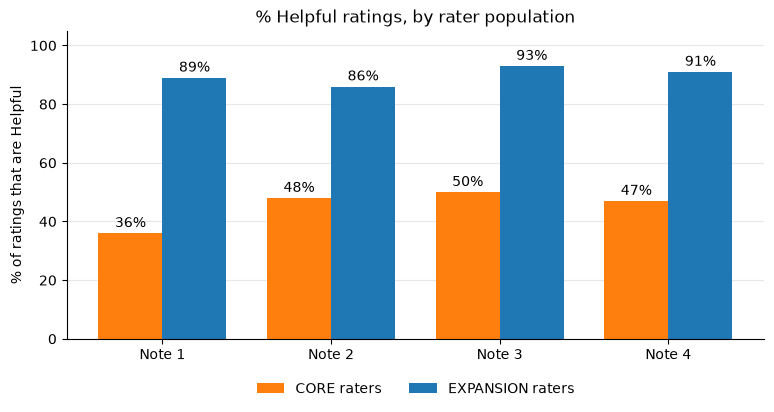

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
bar_width = 0.38
positions = list(range(len(NOTE_ORDER)))
core_positions = [position - bar_width / 2 for position in positions]
expansion_positions = [position + bar_width / 2 for position in positions]

core_bars = ax.bar(core_positions, helpful_share_by_population["CORE"], bar_width, color=ORANGE, label="CORE raters")
expansion_bars = ax.bar(expansion_positions, helpful_share_by_population["EXPANSION"], bar_width, color=BLUE, label="EXPANSION raters")
ax.bar_label(core_bars, fmt="%.0f%%", padding=2)
ax.bar_label(expansion_bars, fmt="%.0f%%", padding=2)

ax.set_xticks(positions, NOTE_ORDER)
ax.set_ylim(0, 105)
ax.set_title("% Helpful ratings, by rater population")
ax.set_ylabel("% of ratings that are Helpful")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax.grid(axis="x", visible=False)
plt.show()

The two populations **disagreed strongly**: EXPANSION raters rated every note Helpful **86–93%** of the time,
CORE raters only **36–50%**. Because CORE raters were split, X's main model gave **no decision**, and the
**Expansion model** decided instead. It chose **Note 4** (this happened for only about 4% of the 500 notes).

## 6. Time

### 6.1 How did ratings arrive over time?

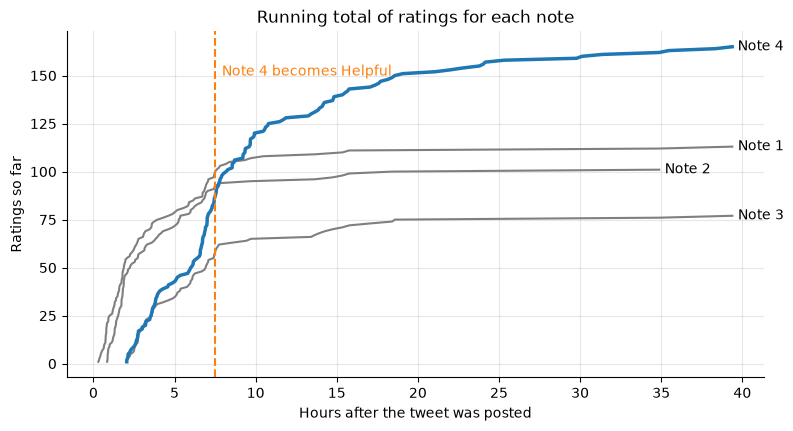

In [16]:
ratings["hours after tweet"] = (to_utc(ratings["createdAtMillis"]) - tweet_posted).dt.total_seconds() / 3600
helpful_at = to_utc(helpful_note_status["timestampMillisOfFirstNonNMRStatus"])
helpful_at_hours = (helpful_at - tweet_posted).total_seconds() / 3600

fig, ax = plt.subplots(figsize=(9, 4.5))
for note_name in NOTE_ORDER:
    note_ratings = ratings[ratings["note"] == note_name].sort_values("hours after tweet")
    hours = note_ratings["hours after tweet"].tolist()
    running_total = list(range(1, len(hours) + 1))

    is_shown_note = note_name == "Note 4"
    color = BLUE if is_shown_note else GRAY
    width = 2.5 if is_shown_note else 1.5
    ax.plot(hours, running_total, color=color, linewidth=width)
    ax.annotate(note_name, (hours[-1], running_total[-1]), xytext=(4, 0), textcoords="offset points", va="center")

ax.axvline(helpful_at_hours, color=ORANGE, linestyle="--", linewidth=1.5)
ax.annotate("Note 4 becomes Helpful", (helpful_at_hours, 150), xytext=(5, 0), textcoords="offset points", color=ORANGE)
ax.set_title("Running total of ratings for each note")
ax.set_xlabel("Hours after the tweet was posted")
ax.set_ylabel("Ratings so far")
plt.show()

Notes 1–3 got ratings first, but **Note 4 caught up fast**, even though it was written last.
After Note 4 was shown, the **other notes almost stopped getting ratings**: raters' attention moved to the shown note.

### 6.2 How long until Note 4 became Helpful?

In [17]:
note_4_written = to_utc(notes[notes["noteId"] == HELPFUL_NOTE_ID].iloc[0]["createdAtMillis"])
hours_note_to_helpful = (helpful_at - note_4_written).total_seconds() / 3600

ratings_before_helpful = ratings[
    (ratings["noteId"] == HELPFUL_NOTE_ID)
    & (to_utc(ratings["createdAtMillis"]) <= helpful_at)
]

print(f"Hours from writing Note 4 to Helpful:  {hours_note_to_helpful:.1f}  (median of 500 notes: 7.9)")
print(f"Hours from the tweet to Helpful:       {helpful_at_hours:.1f}")
print("Ratings Note 4 had at that moment:    ", len(ratings_before_helpful))

Hours from writing Note 4 to Helpful:  5.5  (median of 500 notes: 7.9)
Hours from the tweet to Helpful:       7.5
Ratings Note 4 had at that moment:     86


Note 4 became Helpful **5.5 hours** after it was written, faster than the typical 7.9 hours,
when it had **86 ratings**. Counted from the tweet, that is **7.5 hours**: the misleading tweet was seen
for its most active hours **before** the note appeared.

## 7. Were the AI-written notes different from the human-written notes?

In [18]:
comparison = writers[["writer type"]].copy()
comparison["minutes after tweet"] = [row["minutes after tweet"] for row in timeline_rows[1:5]]
comparison["length (characters)"] = [row["length (characters)"] for row in note_rows]
comparison["ratings"] = level_counts["total"]
comparison["% Helpful"] = level_counts["% Helpful"]
comparison["shown on X"] = level_counts["shown on X"]
comparison

,writer type,minutes after tweet,length (characters),ratings,% Helpful,shown on X
note,,,,,,
Note 1,Human,16,309,113,77.0,False
Note 2,AI,48,540,101,76.2,False
Note 3,AI,118,549,77,83.1,False
Note 4,Human,120,245,165,81.8,True


In this case the **human-written Note 4 won**, and the two AI notes did not.
Like in the 500-note dataset, the AI notes are about **twice as long** (540 and 549 characters vs 309 and 245).
The AI notes were not first (a human wrote Note 1 after 16 minutes) and were not rated worse (Note 3 had the highest % Helpful).
They lost because the rater groups did not agree on them (5.3). One tweet is not enough to say AI notes do worse in general.